# Premier League match results — the goals pipeline

**Question.** For a given fixture, what is the probability of *every* market you might
want: home win, over 2.5, home multigol 1-3, both teams to score, a 2-1 scoreline?

**The idea that organises everything here.** All of those are different questions about
the same object — the joint distribution of (home goals, away goals). Model that
distribution once, and every market is a projection of it:

```
                          away goals
                     0     1     2     3   ...
              0   [ .08  .09  .05  .02 ]        home win   = sum below the diagonal
  home        1   [ .11  .13  .07  .03 ]        draw       = the diagonal
  goals       2   [ .08  .10  .05  .02 ]        over 2.5   = sum where h + a > 2.5
              3   [ .04  .05  .03  .01 ]        home 1-3   = sum of rows 1..3
             ...
```

Two things follow. The quoted probabilities **cannot contradict each other** — over 2.5
and under 2.5 sum to exactly 1, by construction rather than by luck. And a new market
costs a function, not a new model.

---

### The headline, up front

| | |
|---|---|
| Walk-forward 1X2 ranked probability score | **0.1975** (5 seasons) |
| The market's closing line, same matches | **0.1949** - ahead in all five |
| Does disagreeing with the line add information? | **no** - the model trails it in all five seasons |

**The model does not beat the closing line, so its disagreements with it are model error, not information.**
Section 8 shows the numbers. It is a well-calibrated second opinion to start an analysis
from — not an edge. Everything below is written so you can check that claim rather than
take it on trust.

Run order: `build_match_table.py` → this notebook.

In [1]:
import sys, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

MM_DIR = Path.cwd() if (Path.cwd() / "score_matrix.py").exists() else Path.cwd() / "match_model"
sys.path.insert(0, str(MM_DIR))

import config, score_matrix, ratings, modelling, odds as odds_mod

print("match-model dir:", MM_DIR)
print("seasons        :", config.ALL_SEASONS[0], "->", config.ALL_SEASONS[-1])
print("markets quoted :", len(config.MARKETS))

match-model dir: <repo>\match_model
seasons        : 2017-2018 -> 2026-2027
markets quoted : 19


---
## 1. The score matrix, and why it is not two Poissons

Independent Poisson scoring rates get the shape of a football score roughly right, and
get four cells reliably wrong: real matches produce **more 0-0 and 1-1**, and **fewer 1-0
and 0-1**, than independence implies. Teams at 0-0 late play differently from teams at
2-2.

Dixon & Coles (1997) fix exactly those four cells with one parameter, `rho`. Nothing else
in the matrix is touched.

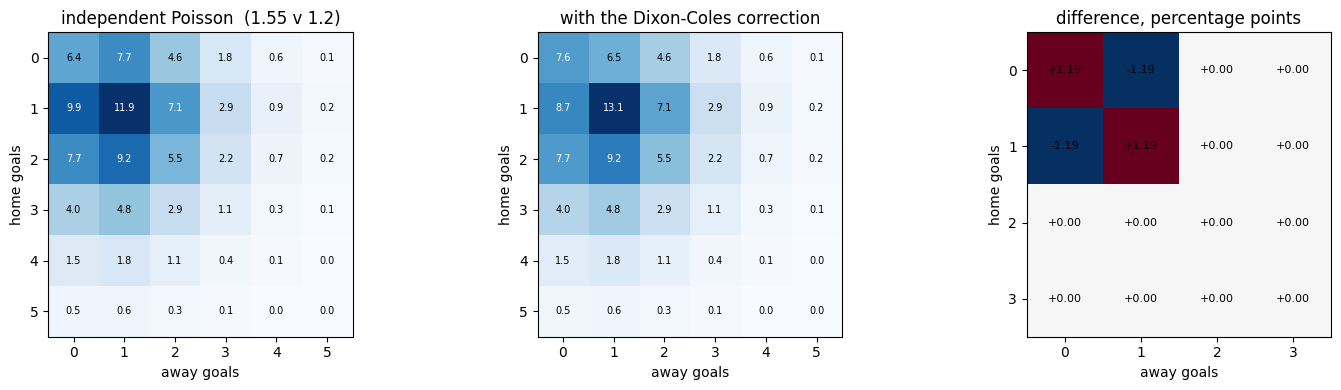

Only the 2x2 block in the corner moves: 0-0 and 1-1 up, 1-0 and 0-1 down.


In [2]:
lam_h, lam_a = 1.55, 1.20
m0 = score_matrix.score_matrix(lam_h, lam_a, rho=0.0, max_goals=config.MAX_GOALS)
mr = score_matrix.score_matrix(lam_h, lam_a, rho=-0.10, max_goals=config.MAX_GOALS)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
im = axes[0].imshow(m0[:6, :6], cmap="Blues")
axes[0].set_title(f"independent Poisson  ({lam_h} v {lam_a})")
for ax, mat, title in [(axes[0], m0, ""), (axes[1], mr, "with the Dixon-Coles correction")]:
    ax.imshow(mat[:6, :6], cmap="Blues")
    ax.set_xlabel("away goals"); ax.set_ylabel("home goals")
    ax.set_xticks(range(6)); ax.set_yticks(range(6))
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f"{mat[i, j]*100:.1f}", ha="center", va="center", fontsize=7,
                    color="white" if mat[i, j] > mat[:6,:6].max()*0.55 else "black")
axes[1].set_title("with the Dixon-Coles correction")

delta = (mr - m0)[:4, :4] * 100
axes[2].imshow(delta, cmap="RdBu_r", vmin=-abs(delta).max(), vmax=abs(delta).max())
axes[2].set_title("difference, percentage points")
axes[2].set_xlabel("away goals"); axes[2].set_ylabel("home goals")
axes[2].set_xticks(range(4)); axes[2].set_yticks(range(4))
for i in range(4):
    for j in range(4):
        axes[2].text(j, i, f"{delta[i, j]:+.2f}", ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.show()

print("Only the 2x2 block in the corner moves: 0-0 and 1-1 up, 1-0 and 0-1 down.")

### Every market is a projection

Same matrix, read four different ways. The coherence checks below are not decoration —
they are what makes it safe to quote several markets on the same fixture.

In [3]:
m = score_matrix.score_matrix(1.55, 1.20, rho=-0.04, max_goals=config.MAX_GOALS)
probs = score_matrix.all_markets(m, config.MARKETS)
for name, p in probs.items():
    print(f"  {name:<22}{p:>8.2%}")

print()
hda = probs['home_win'] + probs['draw'] + probs['away_win']
ou  = score_matrix.market_probability(m, 'total_over', 2.5) + \
      score_matrix.market_probability(m, 'total_under', 2.5)
p0  = 1 - score_matrix.market_probability(m, 'team_over', ('home', 0.5))
p4  = score_matrix.market_probability(m, 'team_over', ('home', 3.5))
print(f"home + draw + away              = {hda:.12f}")
print(f"over 2.5 + under 2.5            = {ou:.12f}")
print(f"home 0 + home 1-3 + home 4+     = {p0 + probs['home_multigol_1_3'] + p4:.12f}")
print("\nThese are exact, not approximate: they are the same numbers added up differently.")

  home_win                44.94%
  draw                    26.05%
  away_win                29.01%
  over_0.5                93.13%
  over_1.5                76.50%
  over_2.5                51.85%
  over_3.5                29.70%
  btts                    55.52%
  home_multigol_1_3       71.57%
  home_multigol_1_2       58.39%
  home_multigol_2_3       38.67%
  away_multigol_1_3       66.50%
  total_multigol_1_3      63.44%
  total_multigol_2_3      46.81%
  total_multigol_2_4      62.04%
  home_over_0.5           78.78%
  home_over_1.5           45.88%
  away_over_0.5           69.88%
  away_over_1.5           33.74%

home + draw + away              = 1.000000000000
over 2.5 + under 2.5            = 1.000000000000
home 0 + home 1-3 + home 4+     = 1.000000000000

These are exact, not approximate: they are the same numbers added up differently.


### Why the grid goes to 14 goals, not 10

The matrix is renormalised after truncation, so whatever tail you cut off gets
redistributed across *every* cell. On an even fixture that is invisible. On a lopsided
one it is not — and "home multigol 1-3" is exactly the kind of market that notices.

In [4]:
rows = []
for lh, la in [(1.6, 1.2), (2.5, 1.0), (4.2, 0.4), (4.5, 2.0)]:
    ref = score_matrix.score_matrix(lh, la, 0.0, 22)
    for mg in (8, 10, 12, 14):
        cut = score_matrix.score_matrix(lh, la, 0.0, mg)
        rows.append({
            "lambda": f"{lh} v {la}", "max_goals": mg,
            "home 1-3 error (pp)": 100 * abs(
                score_matrix.market_probability(cut, "team_range", ("home", 1, 3))
                - score_matrix.market_probability(ref, "team_range", ("home", 1, 3))),
        })
err = pd.DataFrame(rows).pivot(index="lambda", columns="max_goals",
                               values="home 1-3 error (pp)")
print(err.to_string(float_format=lambda v: f"{v:.4f}"))
print(f"\nconfig.MAX_GOALS = {config.MAX_GOALS}")

max_goals     8      10     12     14
lambda                               
1.6 v 1.2 0.0033 0.0001 0.0000 0.0000
2.5 v 1.0 0.0771 0.0042 0.0002 0.0000
4.2 v 0.4 1.0931 0.1554 0.0164 0.0013
4.5 v 2.0 1.3892 0.2223 0.0267 0.0024

config.MAX_GOALS = 14


---
## 2. The data

One row per team per match (6,932), collapsed to one row per match (3,466) for scoring.
Goals come from FBref as *players' goals plus the opponent's own goals*; expected goals
are summed from the shot-level files -- for the seasons that still have them; FBref
stopped publishing shot data after 2024-25, so 2025-26 and 2026-27 carry no xG.

2026-27 is in progress (46 matches played), and it is here for the **ratings and the
rolling form** rather than for evaluation: Dixon-Coles strengths have to be current for
today's fixture to be rated. Every evaluation below still ends on a complete season.

In [5]:
if not config.TEAM_MATCH_PATH.exists():
    subprocess.run([sys.executable, str(MM_DIR / "build_match_table.py")], cwd=str(MM_DIR))

tm = pd.read_parquet(config.TEAM_MATCH_PATH)
match = pd.read_parquet(config.MATCH_DATASET_PATH)
print(f"team-match rows {len(tm):,}   matches {len(match):,}")
print(f"home win {(match.result=='H').mean():.4f}   draw {(match.result=='D').mean():.4f}"
      f"   away win {(match.result=='A').mean():.4f}")
print(f"mean goals {match.total_goals.mean():.3f}   over 2.5 {(match.total_goals>2.5).mean():.4f}")

team-match rows 6,932   matches 3,466
home win 0.4403   draw 0.2346   away win 0.3252
mean goals 2.839   over 2.5 0.5441


### An independent check on the scorelines

FBref and football-data.co.uk record results separately. If the goal reconstruction were
wrong — a missed own goal, a mis-joined row — they would disagree. They do not, on any
match, which is asserted in the test suite so a future regression fails loudly.

In [6]:
both = match[match.fd_home_goals.notna()]
agree = ((both.home_goals == both.fd_home_goals) & (both.away_goals == both.fd_away_goals)).mean()
print(f"scoreline agreement: {agree:.4%} of {len(both):,} matches")
print(f"matches carrying a closing line: {match.mkt_lambda_home.notna().sum():,} / {len(match):,}")

scoreline agreement: 100.0000% of 3,460 matches
matches carrying a closing line: 3,460 / 3,466


### Goals are xG plus noise — and the noise does not repeat

This is the whole reason the model reads xG rather than goals. A team's *past goals* are
a noisier signal of its *future goals* than its past xG is, because finishing variance
does not carry over.

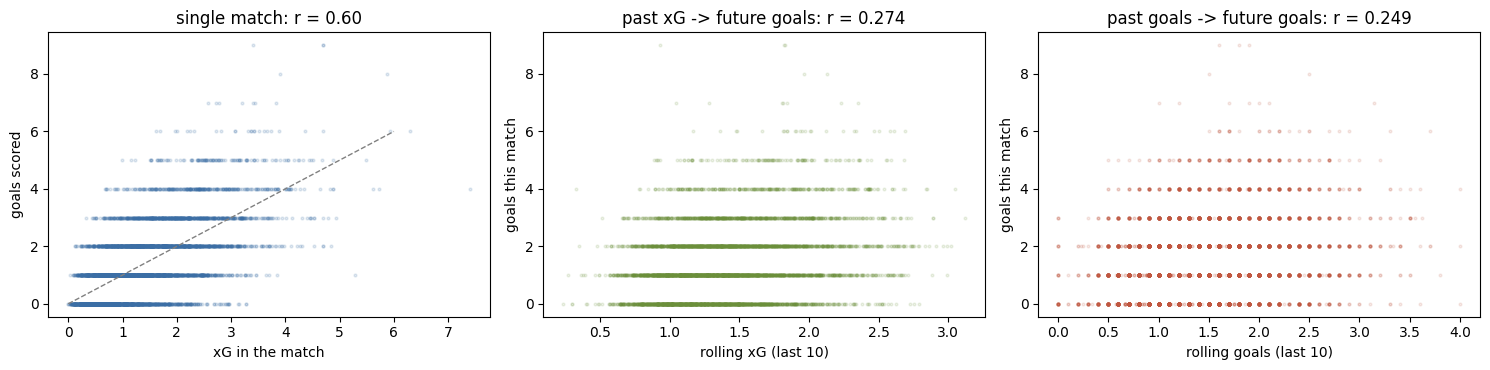

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

axes[0].scatter(tm.shot_xg, tm.goals_for, s=4, alpha=0.15, color="#3b6ea5")
axes[0].plot([0, 6], [0, 6], "--", c="grey", lw=1)
axes[0].set_xlabel("xG in the match"); axes[0].set_ylabel("goals scored")
axes[0].set_title(f"single match: r = {tm.shot_xg.corr(tm.goals_for):.2f}")

d = tm.dropna(subset=["xg_for_roll", "goals_for_roll"])
axes[1].scatter(d.xg_for_roll, d.goals_for, s=4, alpha=0.12, color="#6b8f3a")
axes[1].set_xlabel("rolling xG (last 10)"); axes[1].set_ylabel("goals this match")
axes[1].set_title(f"past xG -> future goals: r = {d.xg_for_roll.corr(d.goals_for):.3f}")

axes[2].scatter(d.goals_for_roll, d.goals_for, s=4, alpha=0.12, color="#c0563f")
axes[2].set_xlabel("rolling goals (last 10)"); axes[2].set_ylabel("goals this match")
axes[2].set_title(f"past goals -> future goals: r = {d.goals_for_roll.corr(d.goals_for):.3f}")
plt.tight_layout(); plt.show()

---
## 3. Dixon-Coles ratings

Attack and defence per club, one home advantage, fitted by maximum likelihood with an
exponential time decay so last month counts for more than two seasons ago.

Why bother, when there is a gradient-boosted model too? Because a rolling average blurs
*who* the form was against. Dixon-Coles solves for strength and schedule together, so a
side that has just played the top four is not mistaken for a side in decline. The two
disagree in useful ways, which is why they get blended.

fitted on 3,040 matches | converged=True
home advantage 0.1368  ->  1.147x more goals at home
rho            -0.0040


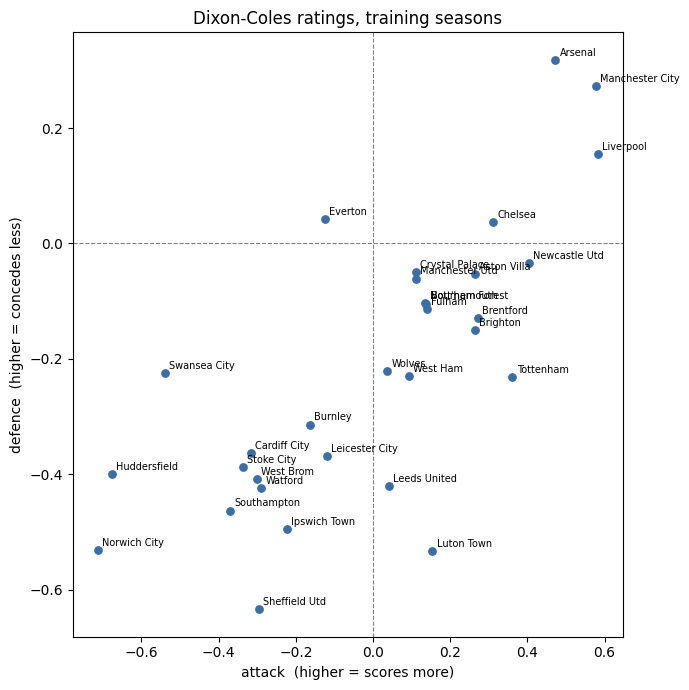

In [8]:
train = match[match.season.isin(config.BURN_IN_SEASONS + config.TRAIN_SEASONS)]
dc = ratings.fit(train, xi=config.DC_XI)
print(f"fitted on {dc.n_matches:,} matches | converged={dc.converged}")
print(f"home advantage {dc.home_adv:.4f}  ->  {np.exp(dc.home_adv):.3f}x more goals at home")
print(f"rho            {dc.rho:+.4f}")

tb = dc.table()
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(tb.attack, tb.defence, s=28, color="#3b6ea5")
for _, r in tb.iterrows():
    ax.annotate(r.team, (r.attack, r.defence), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.axhline(0, ls="--", c="grey", lw=0.8); ax.axvline(0, ls="--", c="grey", lw=0.8)
ax.set_xlabel("attack  (higher = scores more)")
ax.set_ylabel("defence  (higher = concedes less)")
ax.set_title("Dixon-Coles ratings, training seasons")
plt.tight_layout(); plt.show()

Top right is good at both. The interesting clubs are the off-diagonal ones — strong
attack with a leaky defence is exactly the profile that makes *over* markets attractive
and *win* markets unreliable.

In [9]:
for h, a in [("Manchester City", "Norwich City"), ("Norwich City", "Manchester City"),
             ("Arsenal", "Tottenham"), ("Burnley", "Crystal Palace")]:
    lh, la = dc.rate(h, a)
    mm = score_matrix.score_matrix(lh, la, rho=dc.rho, max_goals=config.MAX_GOALS)
    p = score_matrix.all_markets(mm, config.MARKETS)
    print(f"{h:>16s} v {a:<16s}  lambda {lh:.2f}-{la:.2f}   "
          f"home {p['home_win']:.0%}  draw {p['draw']:.0%}  away {p['away_win']:.0%}  "
          f"o2.5 {p['over_2.5']:.0%}")

 Manchester City v Norwich City      lambda 3.47-0.37   home 92%  draw 6%  away 2%  o2.5 74%
    Norwich City v Manchester City   lambda 0.43-3.03   home 3%  draw 9%  away 88%  o2.5 67%
         Arsenal v Tottenham         lambda 2.32-1.04   home 66%  draw 19%  away 16%  o2.5 65%
         Burnley v Crystal Palace    lambda 1.02-1.53   home 25%  draw 26%  away 49%  o2.5 47%


---
## 4. Inverting the market

The market's three 1X2 prices imply probabilities that sum to more than one; the
excess is the margin. Strip it, and the de-vigged 1X2 and over/under 2.5 prices pin down
the pair of scoring rates a Dixon-Coles match would need in order to produce them.

Those two numbers summarise everything the market knows that never reaches a stats feed —
injuries, rotation, motivation, weather. They are the single strongest feature available,
and later they are also the benchmark.

3,460 matches priced, 3,460 inverted to lambdas


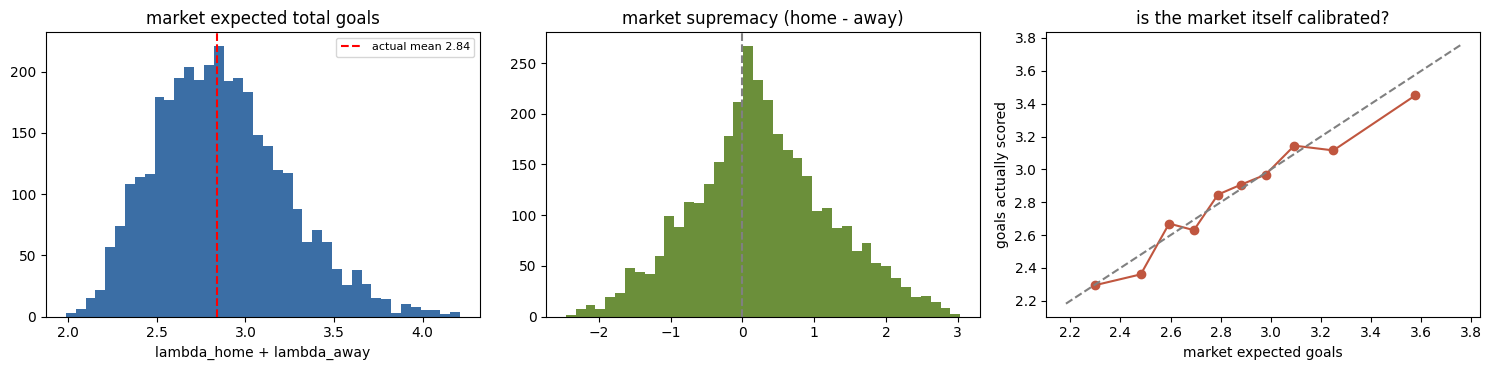

In [10]:
od = odds_mod.load_odds(verbose=False)
print(f"{len(od):,} matches priced, {od.mkt_lambda_home.notna().sum():,} inverted to lambdas")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(od.mkt_total_lambda.dropna(), bins=40, color="#3b6ea5")
axes[0].set_title("market expected total goals"); axes[0].set_xlabel("lambda_home + lambda_away")
axes[0].axvline(match.total_goals.mean(), c="red", ls="--",
                label=f"actual mean {match.total_goals.mean():.2f}")
axes[0].legend(fontsize=8)

sup = od.mkt_lambda_home - od.mkt_lambda_away
axes[1].hist(sup.dropna(), bins=40, color="#6b8f3a")
axes[1].set_title("market supremacy (home - away)"); axes[1].axvline(0, c="grey", ls="--")

mj = match.dropna(subset=["mkt_total_lambda"])
b = pd.qcut(mj.mkt_total_lambda, 10, labels=False, duplicates="drop")
g = mj.groupby(b).agg(pred=("mkt_total_lambda", "mean"), actual=("total_goals", "mean"))
axes[2].plot(g.pred, g.actual, "o-", color="#c0563f")
lims = [g.pred.min() * 0.95, g.pred.max() * 1.05]
axes[2].plot(lims, lims, "--", c="grey")
axes[2].set_xlabel("market expected goals"); axes[2].set_ylabel("goals actually scored")
axes[2].set_title("is the market itself calibrated?")
plt.tight_layout(); plt.show()

The right-hand panel is worth dwelling on: the market's expected total goals tracks the
realised total almost exactly, across the whole range. That is the standard this model is
being held to, and it is a high one.

---
## 5. The boosted model, and the blend

A gradient-boosted Poisson regression (`objective="count:poisson"`, so the output is a
rate rather than a score) on rolling xG, venue-split form, rest, league position and
fixture difficulty. One model serves both sides — `is_home` is a feature.

Its rate and the Dixon-Coles rate are blended **geometrically**, in log space, which is
the natural scale for a multiplicative Poisson model. The weight is chosen on the
validation season, never on the test season.

**Leakage note.** The Dixon-Coles ratings used for a matchweek are refit on matches that
kicked off strictly before it — about 270 refits, warm-started from the previous week.
The cached file is the honest, walk-forward version, not one fit on everything.

In [11]:
dc_path = config.ARTIFACT_DIR / "dc_ratings.parquet"
if dc_path.exists():
    dc_roll = pd.read_parquet(dc_path)
else:
    dc_roll = ratings.rolling_ratings(match, xi=config.DC_XI)
    dc_roll.to_parquet(dc_path, index=False)
print(f"{len(dc_roll):,} of {len(match):,} matches carry a walk-forward rating")
print("(the earliest matches are used only to warm the ratings up)")

# The last COMPLETE season, not config.TEST_SEASONS[0].  The hold-out is now
# 2026-27, which is in progress: 46 matches is too few to read a calibration
# curve off, and the noise floor discussed below assumes a full 380.
season = config.WALK_FORWARD_SEASONS[-1]
past = [s for s in config.ALL_SEASONS if s < season]
valid_season = past[-1]
train_seasons = [s for s in past if s != valid_season and s not in config.BURN_IN_SEASONS]
res = modelling.lambdas_for_split(tm, match, train_seasons, valid_season, season, dc_roll)
print(f"\nblend weight on the boosted model: {res['weight']:.2f}")
print(f"rho fitted on the validation season: {res['rho']:+.4f}")

3,266 of 3,466 matches carry a walk-forward rating
(the earliest matches are used only to warm the ratings up)
  early stopping at iteration 179 (of 1500)
  blend weight on the boosted model: 1.00   rho: -0.0174

blend weight on the boosted model: 1.00
rho fitted on the validation season: -0.0174


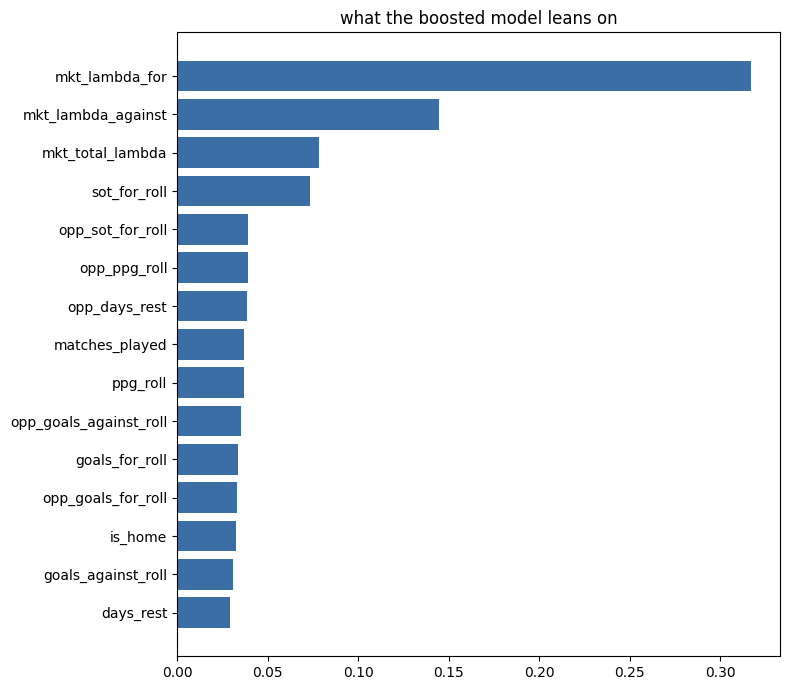

In [12]:
imp = pd.Series(res["model"].booster.feature_importances_,
                index=res["model"].features).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(imp.index, imp.to_numpy(), color="#3b6ea5")
ax.set_title("what the boosted model leans on")
plt.tight_layout(); plt.show()

---
## 6. Is it calibrated?

Calibration is the property that actually matters for a starting-point model: when it says
62%, that should happen 62% of the time. Accuracy without calibration gives you a ranking
you cannot size a decision by.

The grey band is the **noise floor** — the ECE you would see from perfectly calibrated
probabilities given this many matches. Without it, an ECE of 0.05 looks alarming when it
is in fact the best achievable on 380 matches.

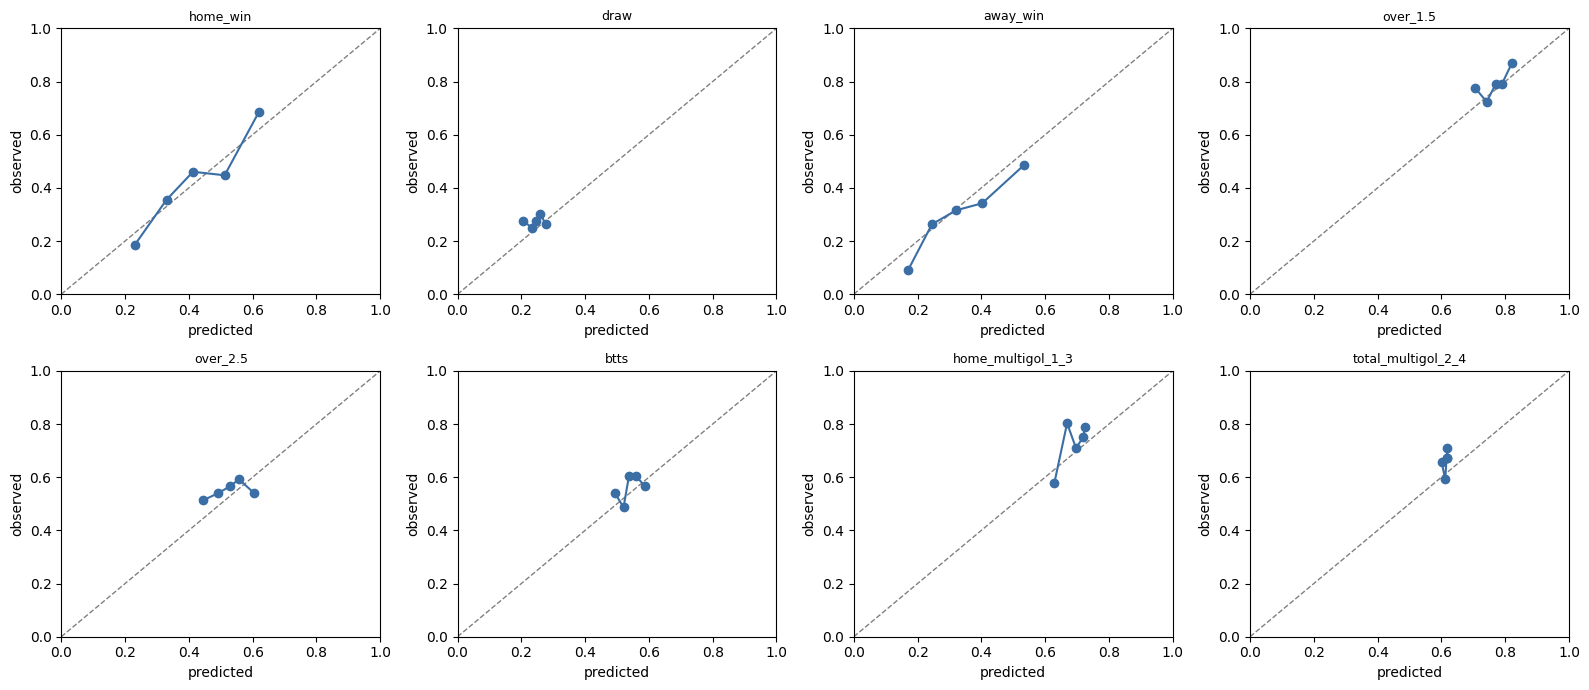

In [13]:
probs_te = modelling.market_frame(res["lam_home"], res["lam_away"], res["rho"], config)
m_te = res["match"]

show = ["home_win", "draw", "away_win", "over_1.5", "over_2.5",
        "btts", "home_multigol_1_3", "total_multigol_2_4"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, name in zip(axes.ravel(), show):
    p = probs_te[name].to_numpy()
    y = modelling.MARKET_OUTCOME[name](m_te.home_goals.to_numpy(),
                                       m_te.away_goals.to_numpy()).astype(float)
    b = pd.qcut(pd.Series(p), 5, labels=False, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": y, "b": b}).groupby("b").mean()
    ax.plot([0, 1], [0, 1], "--", c="grey", lw=1)
    ax.plot(g.p, g.y, "o-", color="#3b6ea5")
    ax.set_title(name, fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("predicted"); ax.set_ylabel("observed")
plt.tight_layout(); plt.show()

In [14]:
ev = modelling.evaluate_markets(m_te, probs_te, config)
ev["within_noise"] = np.where(ev.ece <= ev.ece_floor, "yes", "no")
print(ev[["market", "n", "base_rate", "mean_pred", "log_loss", "ece",
          "ece_floor", "within_noise"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))

            market   n  base_rate  mean_pred  log_loss    ece  ece_floor within_noise
          home_win 380     0.4263     0.4207    0.6308 0.0496     0.0432           no
              draw 380     0.2737     0.2443    0.5893 0.0345     0.0392          yes
          away_win 380     0.3000     0.3349    0.5755 0.0422     0.0413           no
          over_0.5 380     0.9289     0.9346    0.2541 0.0171     0.0224          yes
          over_1.5 380     0.7895     0.7654    0.5134 0.0314     0.0385          yes
          over_2.5 380     0.5500     0.5254    0.6915 0.0509     0.0454           no
          over_3.5 380     0.2842     0.3056    0.6036 0.0507     0.0418           no
              btts 380     0.5605     0.5396    0.6835 0.0435     0.0455          yes
 home_multigol_1_3 380     0.7263     0.6877    0.5818 0.0586     0.0423           no
 home_multigol_1_2 380     0.5605     0.5659    0.6859 0.0301     0.0453          yes
 home_multigol_2_3 380     0.4368     0.3597    0.6898

---
## 7. Walk-forward, against the closing line

Five complete seasons, each priced by a model that saw only the seasons before it, scored
with the
**ranked probability score** — the standard 1X2 metric, which unlike log-loss respects
the ordering of home / draw / away, so predicting a draw when the away side wins costs
less than predicting the home side. Lower is better.

           model  closing line    gap
season                               
2021-2022 0.1922        0.1890 0.0032
2022-2023 0.2025        0.1991 0.0034
2023-2024 0.1857        0.1838 0.0019
2024-2025 0.1985        0.1974 0.0011
2025-2026 0.2085        0.2053 0.0032

mean: model 0.1975   line 0.1949


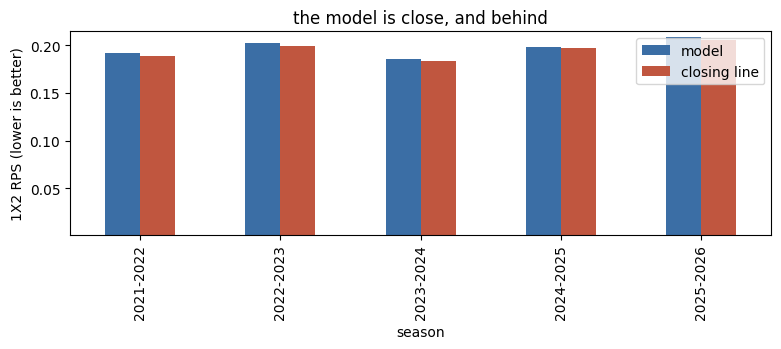

In [15]:
rows = []
for s in config.WALK_FORWARD_SEASONS:
    past = [x for x in config.ALL_SEASONS if x < s]
    vs = past[-1]
    ts = [x for x in past if x != vs and x not in config.BURN_IN_SEASONS]
    r = modelling.lambdas_for_split(tm, match, ts, vs, s, dc_roll, verbose=False)
    pr = modelling.market_frame(r["lam_home"], r["lam_away"], r["rho"], config)
    mt = r["match"]
    rows.append({
        "season": s,
        "model": modelling.rps(mt, pr),
        "closing line": modelling.rps(mt, modelling.market_probs_from_odds(mt, config)),
    })
wf = pd.DataFrame(rows).set_index("season")
wf["gap"] = wf["model"] - wf["closing line"]
print(wf.to_string(float_format=lambda v: f"{v:.4f}"))
print(f"\nmean: model {wf['model'].mean():.4f}   line {wf['closing line'].mean():.4f}")

ax = wf[["model", "closing line"]].plot(kind="bar", figsize=(8, 3.6),
                                        color=["#3b6ea5", "#c0563f"])
ax.set_ylabel("1X2 RPS (lower is better)")
ax.set_ylim(wf.min().min() * 0.95, wf.max().max() * 1.03)
ax.set_title("the model is close, and behind")
plt.tight_layout(); plt.show()

The line wins every one of the five seasons. That is the expected result — the closing price
aggregates money from people who know about team news, and this model does not know the
team news. It is also why the next section exists.

---
## 8. The question that actually matters: does the disagreement carry information?

A good calibration score is not the same as an edge. What matters is whether the places
where the model disagrees with the line are places where the line is wrong. Section 7
already answers it: the closing line scores better than the model in all five seasons, so
a disagreement is far more likely to be the model's error than the market's. Filtering for
larger disagreements does not rescue it, for the same reason - it selects for larger model
errors.

### So what is this for?

A calibrated prior you did not have to form yourself. Used as a starting point it is
genuinely useful:

* it quotes every market consistently, so you can compare a multigol to an over/under;
* it says which fixtures it finds *uncertain*, which is where reading team news pays most;
* it flags where it disagrees with the line, which is a shortlist for a closer look - not
  a signal to act on.

What would actually move it is **team news**: line-ups, injuries and rotation are most of
the gap, and they are the one input the closing line has that this model does not.


---
## 9. Using it

`predict.py` quotes a whole matchweek against the line. The `edge` column is a
disagreement, not a gain.

In [17]:
out = subprocess.run([sys.executable, str(MM_DIR / "predict.py"),
                      "--season", config.WALK_FORWARD_SEASONS[-1],
                      "--matchweek", "30"],
                     capture_output=True, text=True, cwd=str(MM_DIR))
print(out.stdout[:5200])


2025-2026  matchweek 30   (model trained only on earlier seasons; rho = -0.0174, blend weight 1.00)

Burnley  v  Bournemouth      actual: 0-0
expected goals   Burnley: 1.15    Bournemouth: 1.81    total: 2.96
most likely      Bournemouth win at 52.6%  (clear favourite; next best 23.9%)

market                   model    line    edge   confidence
--------------------------------------------------------------------------
Home win                23.9%   23.5%    +0.5   unlikely
Draw                    23.4%   24.6%    -1.2   unlikely
Away win                52.6%   51.9%    +0.7   toss-up
Over 1.5 goals          79.7%   78.4%    +1.2   likely
Over 2.5 goals          56.8%   55.6%    +1.2   toss-up
Over 3.5 goals          34.4%   32.9%    +1.5   leans no
Both teams score        57.3%   55.9%    +1.5   toss-up
Home multigol 1-3       65.4%   64.5%    +0.8   leans yes
Home multigol 1-2       57.4%   57.0%    +0.4   toss-up
Away multigol 1-3       72.6%   72.6%    +0.0   likely
Total multigo

---
## 10. Verification

Everything above rests on the gates in `tests/test_match_model.py`:

* **Coherence** — the matrix is a distribution and the markets cannot contradict.
* **Recovery** — the fitters, run on data simulated from known parameters, get those
  parameters back. This is what separates "the optimiser converged" from "the optimiser
  converged on the right answer".
* **Leakage** — delete every match after a cutoff, rebuild the rolling features, and the
  surviving rows must be bit-identical.

In [18]:
res_t = subprocess.run([sys.executable, str(MM_DIR / "tests" / "test_match_model.py")],
                       capture_output=True, text=True, cwd=str(MM_DIR))
print(res_t.stdout[-3200:])
if res_t.returncode != 0:
    print("STDERR:", res_t.stderr[-1200:])

team-match rows: 6,932   matches: 3,466

--- score matrix coherence ---
[PASS] score matrix sums to 1  -- max error 2.22e-16
[PASS] home + draw + away = 1  -- max error 2.22e-16
[PASS] over 2.5 + under 2.5 = 1  -- max error 2.22e-16
[PASS] multigol 1-3 partitions with 0 and 4+  -- max error 2.22e-16
[PASS] both-teams-score agrees with its complement form  -- max error 2.22e-16
[PASS] with rho = 0 the matrix mean equals lambda
[PASS] negative rho lifts 0-0 and 1-1, lowers 1-0 and 0-1
[PASS] truncating at 14 goals does not move the markets  -- largest move 2.44e-05 across four extreme fixtures

--- parameter recovery ---
[PASS] fit_rho recovers a planted rho  -- planted -0.090, recovered -0.080
[PASS] Dixon-Coles recovers planted attack ratings  -- max abs error 0.091
[PASS] Dixon-Coles recovers planted defence ratings  -- max abs error 0.109
[PASS] Dixon-Coles recovers the home advantage  -- planted 0.220, recovered 0.217
[PASS] Dixon-Coles attack ratings are centred
[PASS] market proba

---
## 11. Limitations, stated plainly

* **It does not beat the closing line.** Use it to form a view, not to find value.
* **One league, ten seasons.** 3,466 matches is thin for the tail markets (over 3.5,
  correct score), where a handful of results moves the estimate.
* **Dixon-Coles has no shrinkage prior.** A promoted club with five matches played is
  rated off those five matches alone: after matchweek 5 of 2026-27, Coventry City sits
  at an attack rating of -1.43 against a league spread of about +/-0.6. It barely
  touches the blended model (the Dixon-Coles weight optimises to ~0 most seasons) but it
  makes `todays_slate.py`'s fair-odds fallback unusable for promoted clubs early in a
  season. See the README's "Known limitations".
* **No team news.** The single biggest omission, and most of the gap to the market.
* **De-vigging is proportional.** Fine at these prices; it understates longshots.
* **FBref stopped publishing shot-level xG.** Newly scraped seasons have no xG. The cost
  is small *provided the odds feed is kept* — walk-forward RPS moves 0.1946 to 0.1949 —
  but it means the football-data feed is now load-bearing rather than a bonus. See
  `../scrape_fbref.py`.